# Projeto 1 — Inteligência Artificial: Distribuição de Alimentos Locais
## Análise Exploratória dos Dados (EDA)

**Unidade Curricular:** Inteligência Artificial · **Ano Letivo:** 2026/2027 · **Curso:** Engenharia de Sistemas Informáticos · **Grupo:** 06

| Nome | Número |
|---|---|
| Guilherme Araujo | 30146 |
| Rodrigo Lopes | 31525 |
| Tomas Gomes | 31501 |
| João Loureiro | 31551 |

## 1. Introdução

Este projeto tem como objetivo desenvolver um agente inteligente capaz de planear rotas de recolha e distribuição de produtos alimentares locais no distrito de Braga. O sistema envolve produtores, clientes, um centro de recolha e uma frota de veículos, e procura rotas eficientes que respeitem os horários de disponibilidade dos produtos, os prazos de entrega e a capacidade dos veículos.

Neste notebook é feita a **Análise Exploratória dos Dados (EDA)** do dataset final do projeto (pasta `data/`). Na primeira fase foi analisado o dataset reduzido `data_tiny` (23 artigos, veículos de 1444,7 kg e 1009,8 kg, sem ficheiro de regras). O dataset final é maior e, sobretudo, **mais restritivo**: tem 80 artigos, veículos de 250 kg e 300 kg, tempos de serviço e um horizonte de dois dias, definidos num novo ficheiro `rules.csv`. Esta análise serve de base à modelação e às decisões tomadas no notebook principal (`01_Project01_G06.ipynb`).

Objetivos da EDA:

1. carregar os 12 ficheiros CSV e verificar a sua integridade;
2. interpretar as regras operacionais (`rules.csv`);
3. analisar as janelas temporais de recolha e de entrega;
4. comparar os pesos encomendados com a capacidade da frota;
5. representar geograficamente as localizações e validar a matriz de distâncias.

## 2. Análise Exploratória dos Dados

### 2.1. Carregamento do Dataset

Os dados são lidos diretamente da pasta `data/` do repositório, sem necessidade de carregar ficheiros manualmente. Se o notebook for aberto no Google Colab sem os ficheiros, a primeira célula clona o repositório do projeto.

In [1]:
import sys
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Pasta dos dados: local (repositório/ZIP) ou, no Colab, clone do repositório
PASTA = Path("data")
if not PASTA.exists() and "google.colab" in sys.modules:
    subprocess.run(["git", "clone", "https://github.com/DevJoaoLoureiro/IA26_P01_G06.git"],
                   check=True)
    PASTA = Path("IA26_P01_G06/data")
assert PASTA.exists(), "Pasta data/ não encontrada: abrir o notebook na pasta do projeto."

# Ler todos os CSV para um dicionário {nome: DataFrame}
dados = {f.stem: pd.read_csv(f) for f in sorted(PASTA.glob("*.csv"))}

pd.DataFrame({"registos": {nome: len(t) for nome, t in dados.items()},
              "colunas": {nome: t.shape[1] for nome, t in dados.items()}})

,registos,colunas
collection_centers,1,5
customers,21,5
delivery_locations,7,5
distance_matrix,182,6
localities,49,6
locations,14,7
order_items,80,9
orders,25,5
producers,6,6
products,31,6


In [2]:
# Valores em falta e registos duplicados em todas as tabelas
pd.DataFrame({
    "valores_em_falta": {n: int(t.isnull().sum().sum()) for n, t in dados.items()},
    "linhas_duplicadas": {n: int(t.duplicated().sum()) for n, t in dados.items()},
})

,valores_em_falta,linhas_duplicadas
collection_centers,0,0
customers,0,0
delivery_locations,0,0
distance_matrix,0,0
localities,0,0
locations,0,0
order_items,0,0
orders,0,0
producers,0,0
products,0,0


#### 2.1.1. Resultados do Carregamento

Foram carregados **12 ficheiros CSV**: 6 produtores, 31 produtos, 21 clientes, 25 encomendas com 80 artigos, 7 locais de entrega, 1 centro de recolha, 2 veículos, 14 localizações, 49 localidades, uma matriz de distâncias com 182 ligações e 10 regras operacionais.

Não existem valores em falta nem linhas duplicadas em nenhuma tabela, pelo que não é necessário qualquer tratamento de dados antes da modelação.

### 2.2. Regras Operacionais (`rules.csv`)

O ficheiro `rules.csv` é a principal novidade do dataset final: define parâmetros que alteram diretamente a modelação do problema.

In [3]:
display(dados["rules"])

,rule,value,description
0,start_date,2026-10-30,first day of the planning horizon
1,horizon_days,2,number of days
2,flow,producer>warehouse>delivery_location,every product goes through the warehouse
3,stop_service_min,10,service time at each pickup / delivery stop
4,warehouse_handling_min,15,time to unload (and to load) a vehicle at the ...
5,max_warehouse_dwell_h,24,max time a product stays in the warehouse (arr...
6,window_semantics,service_start,windows constrain when the service STARTS
7,avg_speed_kmh,45.0,used to build duration_min
8,route_factor,1.3,used to build distance_km
9,generator_seed,1,seed that produced this dataset


#### 2.2.1. Interpretação das Regras

| Regra | Valor | Impacto na modelação |
|---|---|---|
| `start_date`, `horizon_days` | 30/10/2026, 2 dias | Todas as operações terminam até 01/11/2026 às 00:00. |
| `flow` | produtor → armazém → entrega | Nenhum produto vai diretamente do produtor ao cliente: tem de passar pelo centro de recolha. |
| `stop_service_min` | 10 min | Tempo de serviço **por paragem** (recolha ou entrega). Vários artigos recolhidos no mesmo produtor, na mesma visita, contam como uma só paragem. |
| `warehouse_handling_min` | 15 min | Tempo de descarga e carga em cada visita ao armazém. |
| `max_warehouse_dwell_h` | 24 h | Tempo máximo de permanência no armazém. No nosso modelo a carga passa pelo armazém e segue no mesmo veículo (permanência de 0 h), pelo que a regra é sempre cumprida. |
| `window_semantics` | `service_start` | As janelas restringem o **início** do serviço: um veículo pode chegar mais cedo e esperar. |
| `avg_speed_kmh`, `route_factor` | 45 km/h, 1,3 | Parâmetros usados para gerar a matriz de distâncias e tempos (validados na secção 2.8). |

A regra `stop_service_min` merece destaque. Uma primeira versão do modelo contava 10 minutos **por artigo**, e não por paragem. Num produtor com 13 artigos isso somava mais de 2 horas de serviço inexistente e tornava o problema artificialmente impossível. A leitura correta da regra foi decisiva para encontrar soluções completas.

### 2.3. Produtores e Produtos

In [4]:
produtos = dados["products"].merge(dados["producers"][["producer_id", "name"]],
                                   on="producer_id", suffixes=("", "_produtor"))
display(dados["producers"][["producer_id", "name", "locality_id"]])
print("Produtos por produtor e categoria:")
display(pd.crosstab(produtos["name_produtor"], produtos["category"], margins=True,
                    margins_name="Total"))
print("Unidades de venda:", dados["products"]["unit"].value_counts().to_dict())

,producer_id,name,locality_id
0,1,Hortas Valente,24
1,2,Campos Leite,40
2,3,Horta Morais,36
3,4,Courela Carvalho,5
4,5,Horta Antunes,18
5,6,Campos Oliveira,11


Produtos por produtor e categoria:


category,fruit,other,vegetable,Total
name_produtor,,,,
Campos Leite,1,2,2,5
Campos Oliveira,3,0,3,6
Courela Carvalho,1,0,3,4
Horta Antunes,1,0,5,6
Horta Morais,1,0,3,4
Hortas Valente,4,0,2,6
Total,11,2,18,31


Unidades de venda: {'kg': 26, 'crate': 3, 'unit': 2}


#### 2.3.1. Resultados da Análise dos Produtores e Produtos

Existem **6 produtores**, cada um com entre 4 e 6 produtos, num total de **31 produtos**: 18 hortícolas (`vegetable`), 11 frutas (`fruit`) e 2 de outra categoria. A maioria é vendida ao quilo (26 produtos). Os restantes são vendidos à caixa (`crate`) ou à unidade, com um peso unitário próprio.

Cada produto pertence a um único produtor. Por isso, o local de recolha de cada artigo fica completamente determinado pelo produto encomendado.

### 2.4. Veículos e Centro de Recolha

In [5]:
display(dados["vehicles"])
display(dados["collection_centers"])

,vehicle_id,plate,center_id,capacity_kg,refrigerated,avg_speed_kmh
0,1,ZG-06-DP,1,250.0,1,45.0
1,2,TY-74-YA,1,300.0,0,45.0


,center_id,name,locality_id,address,capacity_kg
0,1,Centro de Recolha 1,5,"Travessa Borges, 87",5000.0


#### 2.4.1. Resultados da Análise dos Veículos

A frota tem **2 veículos**, ambos no Centro de Recolha 1 (Braga):

- **Veículo 1 (ZG-06-DP):** 250 kg, refrigerado;
- **Veículo 2 (TY-74-YA):** 300 kg, não refrigerado.

Ambos circulam a uma velocidade média de 45 km/h. A capacidade total da frota é de **550 kg**, muito inferior à do `data_tiny` (mais de 2400 kg). A capacidade passa assim a ser uma restrição relevante (ver secção 2.6).

O dataset não associa nenhum produto à necessidade de refrigeração, pelo que o atributo `refrigerated` não é usado como restrição.

### 2.5. Encomendas e Artigos

In [6]:
artigos = (dados["order_items"]
           .merge(dados["orders"], on="order_id")
           .merge(dados["products"][["product_id", "producer_id", "name", "unit_weight_kg"]],
                  on="product_id"))
for coluna in ["order_datetime", "availability_start", "availability_end",
               "delivery_start", "delivery_end"]:
    artigos[coluna] = pd.to_datetime(artigos[coluna])

print("Estado das encomendas:", dados["orders"]["status"].value_counts().to_dict())
print("Artigos por encomenda:",
      artigos.groupby("order_id").size().describe()[["min", "mean", "max"]].round(1).to_dict())
print("Peso coerente com quantidade × peso unitário:",
      bool(np.allclose(artigos["weight_kg"], artigos["quantity"] * artigos["unit_weight_kg"])))
print("Locais de entrega por tipo:",
      dados["delivery_locations"]["location_type"].value_counts().to_dict())
display(artigos[["order_item_id", "order_id", "name", "producer_id", "delivery_location_id",
                 "weight_kg", "availability_start", "availability_end",
                 "delivery_start", "delivery_end"]].head(10))

Estado das encomendas: {'confirmed': 25}
Artigos por encomenda: {'min': 2.0, 'mean': 3.2, 'max': 6.0}
Peso coerente com quantidade × peso unitário: True
Locais de entrega por tipo: {'restaurant': 3, 'home': 2, 'store': 2}


,order_item_id,order_id,name,producer_id,delivery_location_id,weight_kg,availability_start,availability_end,delivery_start,delivery_end
0,1,1,Curgete,3,5,12.0,2026-10-30 07:45:00,2026-10-30 10:45:00,2026-10-30 12:30:00,2026-10-30 14:30:00
1,2,1,Cereja,6,5,7.4,2026-10-30 08:15:00,2026-10-30 10:15:00,2026-10-30 12:30:00,2026-10-30 14:30:00
2,3,2,Maca,6,4,9.9,2026-10-30 08:15:00,2026-10-30 10:15:00,2026-10-30 13:30:00,2026-10-30 16:45:00
3,4,2,Batata,4,4,17.9,2026-10-30 07:00:00,2026-10-30 09:30:00,2026-10-30 13:30:00,2026-10-30 16:45:00
4,5,2,Laranja,2,4,2.9,2026-10-30 08:45:00,2026-10-30 12:30:00,2026-10-30 13:30:00,2026-10-30 16:45:00
5,6,3,Curgete,2,4,3.0,2026-10-31 08:15:00,2026-10-31 11:00:00,2026-10-31 15:30:00,2026-10-31 17:30:00
6,7,3,Cebola,3,4,2.8,2026-10-31 09:30:00,2026-10-31 11:45:00,2026-10-31 15:30:00,2026-10-31 17:30:00
7,8,3,Pimento,1,4,2.8,2026-10-31 07:45:00,2026-10-31 11:15:00,2026-10-31 15:30:00,2026-10-31 17:30:00
8,9,3,Pera,5,4,4.5,2026-10-31 10:15:00,2026-10-31 14:15:00,2026-10-31 15:30:00,2026-10-31 17:30:00
9,10,4,Cebola,3,4,6.2,2026-10-31 09:30:00,2026-10-31 12:45:00,2026-10-31 16:00:00,2026-10-31 18:15:00


#### 2.5.1. Resultados da Análise das Encomendas

As **25 encomendas** estão todas no estado `confirmed` e têm entre 2 e 6 artigos (3,2 em média), num total de **80 artigos**. O peso de cada artigo (`weight_kg`) é coerente com a quantidade multiplicada pelo peso unitário do produto.

Cada encomenda tem um único local de entrega, e todos os seus artigos partilham a mesma janela de entrega. Os artigos de uma encomenda vêm, no entanto, de produtores diferentes (até 5 numa única encomenda), com janelas de recolha próprias. É por isso que o problema é modelado ao nível do **artigo** (um par recolha/entrega) e não da encomenda.

Os 7 locais de entrega são 3 restaurantes, 2 casas e 2 lojas.

### 2.6. Janelas Temporais

In [7]:
artigos["dia_recolha"] = artigos["availability_start"].dt.strftime("%d/%m")
artigos["dia_entrega"] = artigos["delivery_start"].dt.strftime("%d/%m")
horas = lambda a, b: (b - a).dt.total_seconds() / 3600

verificacoes = {
    "janela de recolha válida (início <= fim)":
        (artigos["availability_start"] <= artigos["availability_end"]).sum(),
    "janela de entrega válida (início <= fim)":
        (artigos["delivery_start"] <= artigos["delivery_end"]).sum(),
    "encomenda feita antes de o produto ficar disponível":
        (artigos["order_datetime"] <= artigos["availability_start"]).sum(),
    "entrega pode começar antes do fim da recolha":
        (artigos["delivery_start"] < artigos["availability_end"]).sum(),
    "entrega termina antes de a recolha começar":
        (artigos["delivery_end"] < artigos["availability_start"]).sum(),
}
display(pd.Series(verificacoes, name="artigos (de 80)").to_frame())

print("Duração das janelas (h):")
display(pd.DataFrame({
    "recolha": horas(artigos["availability_start"], artigos["availability_end"]).describe(),
    "entrega": horas(artigos["delivery_start"], artigos["delivery_end"]).describe(),
}).loc[["min", "mean", "max"]].round(2))

print("Artigos por dia de recolha (linhas) e dia de entrega (colunas):")
display(pd.crosstab(artigos["dia_recolha"], artigos["dia_entrega"], margins=True,
                    margins_name="Total"))

,artigos (de 80)
janela de recolha válida (início <= fim),80
janela de entrega válida (início <= fim),80
encomenda feita antes de o produto ficar disponível,80
entrega pode começar antes do fim da recolha,8
entrega termina antes de a recolha começar,0


Duração das janelas (h):


,recolha,entrega
min,1.50,1.50
mean,2.68,2.50
max,4.00,3.75


Artigos por dia de recolha (linhas) e dia de entrega (colunas):


dia_entrega,30/10,31/10,Total
dia_recolha,,,
30/10,26,20,46
31/10,0,34,34
Total,26,54,80


O teste seguinte verifica se cada artigo pode ser servido **isoladamente**, no melhor caso possível. O veículo parte do centro, recolhe o artigo assim que a janela abre, volta ao armazém e entrega-o. Se um artigo falhar mesmo neste cenário otimista, nenhum algoritmo o consegue servir.

In [8]:
regras = dict(dados["rules"][["rule", "value"]].values)
servico = pd.Timedelta(minutes=float(regras["stop_service_min"]))
armazem = pd.Timedelta(minutes=float(regras["warehouse_handling_min"]))
loc = dados["locations"]
loc_id = {(r.location_type, r.ref_id): r.location_id for r in loc.itertuples()}
minutos = {(r.origin_location_id, r.destination_location_id): r.duration_min
           for r in dados["distance_matrix"].itertuples()}
duracao = lambda a, b: pd.Timedelta(minutes=0 if a == b else minutos[(a, b)])
centro = loc_id[("collection_center", 1)]

folgas = []
for a in artigos.itertuples():
    p = loc_id[("producer", a.producer_id)]
    d = loc_id[("delivery_location", a.delivery_location_id)]
    recolha = max(pd.Timestamp(regras["start_date"]) + duracao(centro, p),
                  a.availability_start, a.order_datetime)
    chegada_entrega = recolha + servico + duracao(p, centro) + armazem + duracao(centro, d)
    inicio_entrega = max(chegada_entrega, a.delivery_start)
    folgas.append((a.delivery_end - inicio_entrega).total_seconds() / 60)
artigos["folga_min"] = folgas

print("Artigos servíveis isoladamente:", (artigos["folga_min"] >= 0).sum(), "de", len(artigos))
print("Folga mínima / mediana (min):", round(artigos["folga_min"].min(), 1),
      "/", round(artigos["folga_min"].median(), 1))
display(artigos.nsmallest(5, "folga_min")[["order_item_id", "order_id", "producer_id",
                                           "delivery_location_id", "availability_start",
                                           "delivery_end", "folga_min"]])

Artigos servíveis isoladamente: 80 de 80
Folga mínima / mediana (min): 90.0 / 150.0


,order_item_id,order_id,producer_id,delivery_location_id,availability_start,delivery_end,folga_min
12,13,5,1,2,2026-10-30 08:30:00,2026-10-31 09:30:00,90.0
13,14,5,5,2,2026-10-30 09:45:00,2026-10-31 09:30:00,90.0
14,15,5,6,2,2026-10-30 08:15:00,2026-10-31 09:30:00,90.0
15,16,5,1,2,2026-10-30 08:15:00,2026-10-31 09:30:00,90.0
24,25,8,4,2,2026-10-31 07:15:00,2026-10-31 15:30:00,105.0


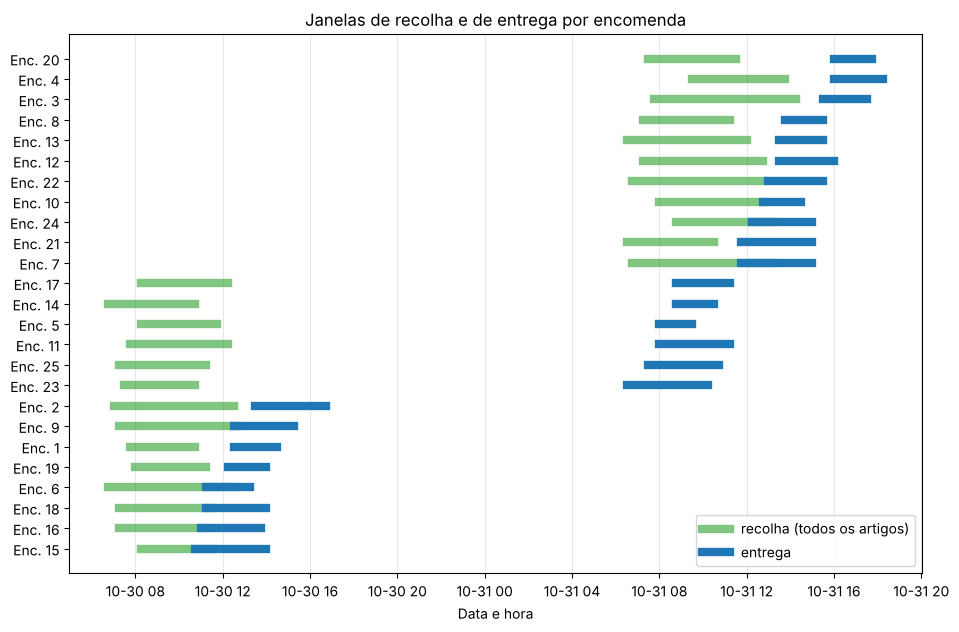

In [9]:
# Janelas por encomenda: recolha (mais cedo/mais tarde entre os artigos) e entrega
janelas = artigos.groupby("order_id").agg(
    rec_ini=("availability_start", "min"), rec_fim=("availability_end", "max"),
    ent_ini=("delivery_start", "first"), ent_fim=("delivery_end", "first")
).sort_values("ent_ini")

fig, ax = plt.subplots(figsize=(11, 7))
for y, (oid, j) in enumerate(janelas.iterrows()):
    ax.plot([j.rec_ini, j.rec_fim], [y, y], color="tab:green", lw=6, alpha=0.6,
            label="recolha (todos os artigos)" if y == 0 else None)
    ax.plot([j.ent_ini, j.ent_fim], [y, y], color="tab:blue", lw=6,
            label="entrega" if y == 0 else None)
ax.set_yticks(range(len(janelas)), [f"Enc. {i}" for i in janelas.index])
ax.set_title("Janelas de recolha e de entrega por encomenda")
ax.set_xlabel("Data e hora")
ax.grid(axis="x", alpha=0.3)
ax.legend(loc="lower right")
plt.show()

#### 2.6.1. Resultados da Análise Temporal

- **Todas as janelas são válidas:** o início é anterior ao fim em todos os 80 artigos.
- **A data da encomenda nunca limita a recolha:** todas as encomendas são feitas antes de o produto ficar disponível. No `data_tiny`, pelo contrário, 12 dos 23 artigos tinham janelas de recolha que terminavam antes da encomenda e tiveram de ser excluídos. No dataset final nenhum artigo é excluído.
- **As janelas são curtas:** entre 1,5 h e 4 h, tanto na recolha como na entrega. Como o horizonte é de 2 dias, os veículos têm de fazer várias viagens bem sincronizadas.
- **Planeamento em dois dias:** 26 artigos são recolhidos e entregues a 30/10, 34 a 31/10, e 20 são recolhidos a 30/10 para serem entregues só a 31/10. Estes 20 artigos ficam no veículo durante a noite e ocupam capacidade.
- **Cada artigo, sozinho, é fácil:** os 80 artigos são servíveis isoladamente, com uma folga mínima de 90 minutos (mediana de 150 minutos). Em 8 artigos a janela de entrega abre antes de terminar a de recolha. A dificuldade do problema não está em nenhum artigo individual, mas em servir **todos em conjunto** com apenas dois veículos: cada desvio para servir um artigo consome tempo que falta para os outros.

O gráfico mostra o padrão típico de cada dia: recolhas de manhã (aproximadamente entre as 06:30 e as 14:30) e entregas a partir do fim da manhã. Isto sugere rotas com uma volta de recolha, passagem pelo armazém e uma volta de entrega.

### 2.7. Pesos e Capacidade da Frota

Peso total dos 80 artigos: 580.0 kg
Capacidade total da frota: 550 kg
Artigo mais pesado: 21.8 kg
Encomenda mais pesada: 38.4 kg (encomenda 18)

Peso a recolher por dia e produtor (kg):


dia_recolha,30/10,31/10,Total
producer_id,,,
1,43.7,14.2,57.9
2,31.5,64.1,95.6
3,50.7,71.1,121.8
4,48.0,32.9,80.9
5,44.3,43.8,88.1
6,120.5,15.2,135.7
Total,338.7,241.3,580.0


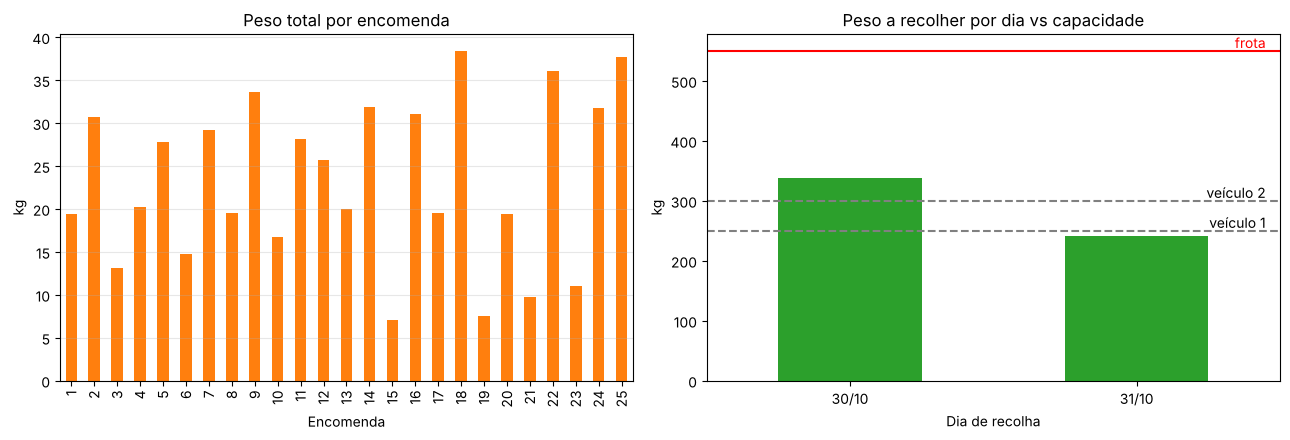

In [10]:
peso_encomenda = artigos.groupby("order_id")["weight_kg"].sum()
capacidade_total = dados["vehicles"]["capacity_kg"].sum()

print(f"Peso total dos 80 artigos: {artigos['weight_kg'].sum():.1f} kg")
print(f"Capacidade total da frota: {capacidade_total:.0f} kg")
print(f"Artigo mais pesado: {artigos['weight_kg'].max():.1f} kg")
print(f"Encomenda mais pesada: {peso_encomenda.max():.1f} kg (encomenda {peso_encomenda.idxmax()})")
print("\nPeso a recolher por dia e produtor (kg):")
display(artigos.pivot_table(index="producer_id", columns="dia_recolha", values="weight_kg",
                            aggfunc="sum", margins=True, margins_name="Total").round(1))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
peso_encomenda.plot.bar(ax=ax[0], color="tab:orange")
ax[0].set_title("Peso total por encomenda")
ax[0].set_xlabel("Encomenda")
ax[0].set_ylabel("kg")
ax[0].grid(axis="y", alpha=0.3)
artigos.groupby("dia_recolha")["weight_kg"].sum().plot.bar(ax=ax[1], color="tab:green")
for _, v in dados["vehicles"].iterrows():
    ax[1].axhline(v.capacity_kg, ls="--", color="gray")
    ax[1].text(1.45, v.capacity_kg + 5, f"veículo {v.vehicle_id}", ha="right")
ax[1].axhline(capacidade_total, ls="-", color="red")
ax[1].text(1.45, capacidade_total + 5, "frota", ha="right", color="red")
ax[1].set_title("Peso a recolher por dia vs capacidade")
ax[1].set_xlabel("Dia de recolha")
ax[1].set_ylabel("kg")
ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

#### 2.7.1. Resultados da Análise de Pesos

O peso total a transportar é de **580 kg**, acima da capacidade conjunta da frota (**550 kg**). Assim, mesmo sem janelas temporais, seria impossível fazer tudo numa única viagem por veículo: as rotas têm de incluir **várias viagens** com passagem pelo armazém.

Individualmente, nenhum artigo (máximo de 21,8 kg) nem nenhuma encomenda (entre 7,1 e 38,4 kg) se aproxima da capacidade de um veículo. A restrição de capacidade surge da **acumulação de carga** numa viagem: no dia 30/10 há 338,7 kg a recolher, mais do que cabe em qualquer um dos veículos, e o produtor 6 sozinho concentra 120,5 kg nessa manhã.

Ao contrário do `data_tiny`, em que a capacidade praticamente não tinha efeito, aqui ela condiciona a forma das rotas.

### 2.8. Localizações e Matriz de Distâncias

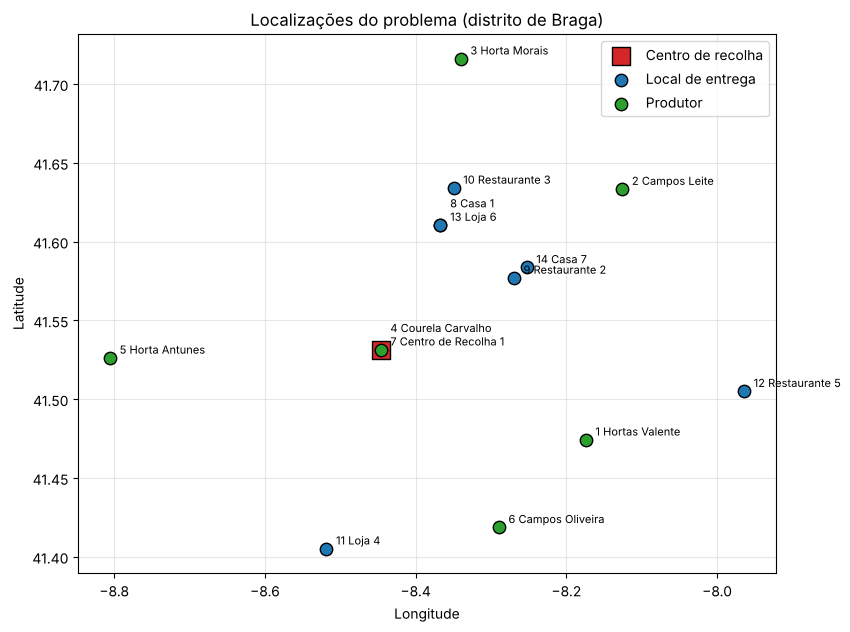

In [11]:
cores = {"producer": "tab:green", "collection_center": "tab:red",
         "delivery_location": "tab:blue"}
nomes = {"producer": "Produtor", "collection_center": "Centro de recolha",
         "delivery_location": "Local de entrega"}

fig, ax = plt.subplots(figsize=(9, 7))
for tipo, grupo in loc.groupby("location_type"):
    ax.scatter(grupo["longitude"], grupo["latitude"], s=160 if tipo == "collection_center" else 80,
               c=cores[tipo], label=nomes[tipo], marker="s" if tipo == "collection_center" else "o",
               edgecolors="black", zorder=3)
# Pontos com as mesmas coordenadas recebem uma única etiqueta (uma linha por ponto)
for (lon, lat), grupo in loc.groupby(["longitude", "latitude"]):
    texto = "\n".join(f"{r.location_id} {r.name}" for r in grupo.itertuples())
    ax.annotate(texto, (lon, lat), textcoords="offset points", xytext=(7, 3), fontsize=8)
ax.set_title("Localizações do problema (distrito de Braga)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

Ligações: 182 (esperado 182 = 14 × 13)
Pares ordenados em falta: 0
Assimetrias: 0
Distâncias negativas: 0 | distâncias nulas: 4
Erro máximo vs. haversine × 1.3: 0.0050 km
Erro máximo vs. tempo a 45 km/h: 0.053 min


,count,mean,std,min,25%,50%,75%,max
distance_km,182.0,30.45,17.14,0.0,18.11,28.69,38.82,91.13


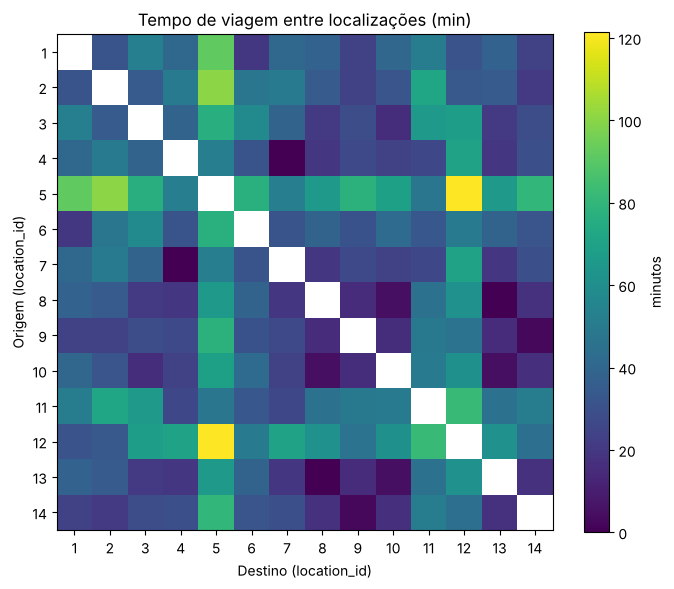

In [12]:
matriz = dados["distance_matrix"]
n = len(loc)
dist = {(r.origin_location_id, r.destination_location_id): r.distance_km for r in matriz.itertuples()}
coords = loc.set_index("location_id")[["latitude", "longitude"]]


def haversine(a, b):
    la1, lo1, la2, lo2 = np.radians([coords.latitude[a], coords.longitude[a],
                                     coords.latitude[b], coords.longitude[b]])
    h = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return 2 * 6371.0088 * np.arcsin(np.sqrt(h))


fator = float(regras["route_factor"])
velocidade = float(regras["avg_speed_kmh"])
erro_dist = max(abs(haversine(a, b) * fator - km) for (a, b), km in dist.items())
erro_tempo = (matriz["distance_km"] / velocidade * 60 - matriz["duration_min"]).abs().max()

print(f"Ligações: {len(matriz)} (esperado {n * (n - 1)} = {n} × {n - 1})")
print("Pares ordenados em falta:",
      sum((a, b) not in dist for a in coords.index for b in coords.index if a != b))
print("Assimetrias:", sum(abs(dist[(a, b)] - dist[(b, a)]) > 1e-9 for a, b in dist))
print("Distâncias negativas:", int((matriz["distance_km"] < 0).sum()),
      "| distâncias nulas:", int((matriz["distance_km"] == 0).sum()))
print(f"Erro máximo vs. haversine × {fator}: {erro_dist:.4f} km")
print(f"Erro máximo vs. tempo a {velocidade:.0f} km/h: {erro_tempo:.3f} min")
display(matriz["distance_km"].describe().round(2).to_frame().T)

tempo = matriz.pivot(index="origin_location_id", columns="destination_location_id",
                     values="duration_min")
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(tempo.values, cmap="viridis")
ax.set_xticks(range(n), tempo.columns)
ax.set_yticks(range(n), tempo.index)
ax.set_xlabel("Destino (location_id)")
ax.set_ylabel("Origem (location_id)")
ax.set_title("Tempo de viagem entre localizações (min)")
fig.colorbar(im, ax=ax, label="minutos")
plt.show()

#### 2.8.1. Resultados das Localizações e da Matriz

Há **14 localizações**: 6 produtores, 1 centro de recolha e 7 locais de entrega. Os pontos espalham-se pelo distrito de Braga, desde Esposende (produtor 5, a oeste) até Cabeceiras de Basto (Restaurante 5, a leste).

A matriz de distâncias está **completa** (182 = 14 × 13 pares ordenados), é **simétrica** e não tem valores negativos. Existem 4 distâncias nulas, que correspondem a dois pares de pontos com as mesmas coordenadas:

- o produtor 4 (Courela Carvalho) e o centro de recolha;
- a Casa 1 e a Loja 6, ambas em Amares.

Confirmámos ainda que a matriz segue exatamente as regras: distância = haversine × 1,3 (erro inferior a 0,005 km) e tempo = distância a 45 km/h. Os tempos de viagem chegam a pouco mais de 2 horas (122 min) entre extremos do distrito (Esposende–Cabeceiras de Basto), o que, com janelas de 1,5 a 4 horas, torna a ordem das visitas determinante.

Estes pontos coincidentes são úteis: recolher no produtor 4 e passar pelo armazém não custa deslocação.

### 2.9. Integridade Referencial

In [13]:
relacoes = [
    ("orders", "customer_id", "customers", "customer_id"),
    ("orders", "delivery_location_id", "delivery_locations", "delivery_location_id"),
    ("order_items", "order_id", "orders", "order_id"),
    ("order_items", "product_id", "products", "product_id"),
    ("products", "producer_id", "producers", "producer_id"),
    ("vehicles", "center_id", "collection_centers", "center_id"),
    ("producers", "locality_id", "localities", "locality_id"),
    ("customers", "locality_id", "localities", "locality_id"),
    ("delivery_locations", "locality_id", "localities", "locality_id"),
    ("collection_centers", "locality_id", "localities", "locality_id"),
]
linhas = []
for origem, chave, destino, chave_destino in relacoes:
    em_falta = ~dados[origem][chave].isin(dados[destino][chave_destino])
    linhas.append({"relação": f"{origem}.{chave} → {destino}.{chave_destino}",
                   "referências inválidas": int(em_falta.sum())})

# Cada produtor, centro e local de entrega tem exatamente uma localização
for tipo, tabela, chave in [("producer", "producers", "producer_id"),
                            ("collection_center", "collection_centers", "center_id"),
                            ("delivery_location", "delivery_locations", "delivery_location_id")]:
    refs = loc[loc["location_type"] == tipo]["ref_id"]
    ok = sorted(refs) == sorted(dados[tabela][chave]) and refs.is_unique
    linhas.append({"relação": f"locations ({tipo}) ↔ {tabela}", "referências inválidas": 0 if ok else 1})
pd.DataFrame(linhas)

,relação,referências inválidas
0,orders.customer_id → customers.customer_id,0
1,orders.delivery_location_id → delivery_locatio...,0
2,order_items.order_id → orders.order_id,0
3,order_items.product_id → products.product_id,0
4,products.producer_id → producers.producer_id,0
5,vehicles.center_id → collection_centers.center_id,0
6,producers.locality_id → localities.locality_id,0
7,customers.locality_id → localities.locality_id,0
8,delivery_locations.locality_id → localities.lo...,0
9,collection_centers.locality_id → localities.lo...,0


#### 2.9.1. Resultados da Integridade Referencial

Todas as chaves estrangeiras apontam para registos existentes. Cada produtor, centro de recolha e local de entrega tem exatamente uma localização em `locations.csv`. Os dados são consistentes e podem ser usados diretamente pelo agente, sem limpeza adicional.

## 3. Conclusão da Análise Exploratória

A EDA mostrou que o dataset final está **completo e consistente**: não há valores em falta, duplicados ou referências inválidas, e a matriz de distâncias é completa, simétrica e coerente com as regras de geração.

As conclusões com impacto direto na modelação são:

1. **Granularidade:** o problema é modelado ao nível do artigo (80 pares recolha/entrega), porque os artigos de uma encomenda vêm de produtores e janelas diferentes.
2. **Fluxo obrigatório:** cada artigo segue o percurso produtor → centro de recolha → local de entrega, no mesmo veículo.
3. **Tempos:** 10 min por paragem (e não por artigo), 15 min por visita ao armazém e janelas aplicadas ao início do serviço, com espera permitida.
4. **Capacidade:** 580 kg de procura contra 550 kg de frota, e 338,7 kg a recolher só no dia 30. São necessárias várias viagens por veículo.
5. **Horizonte de dois dias:** 20 artigos atravessam a noite dentro do veículo.
6. **Nenhum artigo é inviável à partida** (ao contrário do `data_tiny`), por isso o objetivo é entregar **os 80 artigos** e minimizar a distância total.

Estas conclusões são usadas no notebook principal (`01_Project01_G06.ipynb`) na definição das classes `Problem`, `Request`, `Vehicle` e `State`, da função de custo e do verificador de viabilidade.